# load the csv 
# and get the shape ,type 
# descriptive stats = mean , median of each column
# check if there are missing values
# the first 5 rows

In [ ]:
# starter code

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# used to read the csv file for creating the set
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape) # it tells u number of cols and rows
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())  # there are no null values

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

# define resolution_hours - y ie the value to be predicted
# exclude ticket_id bc we dont need it
# to prevent data leakage we only want the available things at the time of the prediction to be there
# these are - complexity_score , team_experience_years 
# lines_changed , reopened are available for an existing project not a new one 
# training data should only have the things we will have at the time of prediction.
# since this is a supervised learning we will provide the label in the training data.

In [ ]:
training_data_prep = df.drop(columns=["lines_changed" , "reopened" , "ticket_id"])

# print(training_data_prep.shape)
# all rows are there but the columns are reduced

# spliting the data into training and test sets
# training data gets randomly shuffled when we choose so
# we have to protect testing data and training data from mixing up.
# spliting steps
# split label and feature - using []
# split training_feature, testing_feature ,training_label , testing_label = train_test( feature , label) 

In [ ]:
label_set = training_data_prep["resolution_hours"]
feature_set = training_data_prep[["team_experience_years" , "complexity_score"]]



feature_to_train_on , feature_to_test_on , label_to_train_on ,label_to_test_on  = train_test_split(
    feature_set , label_set , test_size=0.2 , random_state=42
)

# Dummy Regressor always predicts the value you give it
# here we gave it mean thus it will always give the mean as a predicted value
# used for testing your model , your model needs to be smarter than this prediction
# Test metrics are judges on how well our model is fitting the training sets

In [ ]:
# Dummy Regressor
dummy_model = DummyRegressor(strategy="mean")
# All predictions will be equal the the mean of the label data

dummy_model.fit(feature_to_train_on , label_to_train_on)
# make the model make the prediction ie get the mean of the label of training data
# so it can always use that

# for referene
# print(feature_to_train_on.describe(include="all")) mean - 6.25 and 5.45
# print(label_to_train_on.describe(include="all")) mean - 19.057031

# the line the dummy will produce is y = mean_of_trainings_label
# lets make the model predict on our testing set
# given the features this is the model's predicted labels
dummy_predictions  = dummy_model.predict(feature_to_test_on)
# print(dummy_predictions)


# testing if the data model fits the training data well is checked by checking the errors
# mse , mae , r_2 .. are used to check the deviation between predicted and real values
# u can use them both in training and testing data
# if u use them on testing data it will be better check for validity

# print(dummy_predictions.shape)
# print(label_to_test_on.shape)

# mae - the average of the deviation between actual and predicted values
mae = mean_absolute_error(label_to_test_on ,dummy_predictions)

# # mse - rss / n - squared sum of residuals / n
mse = mean_squared_error(label_to_test_on  , dummy_predictions)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
r2 = r2_score(label_to_test_on ,dummy_predictions )



print("mae = " , mae )
print("mse = " , mse)
print("r squared = " , r2 )
# r2 is negative which implies it is a bad model
# the model isn't even trying to predict on the test dataset



mae =  9.113951822916667
mse =  112.31092313639323
r squared =  -0.021016765260001957


# trying to fit the data better using linear regression models
# the linear regression tries to create a linear line to fit the pattern it sees in the training data

In [ ]:
linear_model = LinearRegression()

linear_model.fit(feature_to_train_on , label_to_train_on)

linear_predictions  = linear_model.predict(feature_to_test_on)


# mae - the average of the deviation between actual and predicted values
linear_mae = mean_absolute_error(label_to_test_on ,linear_predictions)

# # mse - rss / n - squared sum of residuals / n
linear_mse = mean_squared_error(label_to_test_on  , linear_predictions)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
linear_r2 = r2_score(label_to_test_on , linear_predictions )



print("mae = " , linear_mae )
print("mse = " , linear_mse)
print("r squared = " , linear_r2 )
# the mae , mse ,  are far lower here than the dummy so linear is better than dummy
# r squared is higher - 0.884 so it means the linear model covered much of the pattern and distribution seen in the testing set





mae =  2.90601298595026
mse =  12.761144066531239
r squared =  0.8839886480141969


# create a pipeline with polynomial features and StandardScaler
# compare degree 2 and 3 using cross-validation on training set
# first we have a pipeline to preprocess the data to create the matrix with the column for setting up the data
# then do the training

In [ ]:
import matplotlib.pyplot as plt



# since the data is in 2d this plotting wld require a 3d space
# plt.scatter(feature_to_train_on , label_to_train_on , color = "red")
# team_experience_years_training = feature_to_train_on["team_experience_years"]
# complexity_score_training = feature_to_train_on["complexity_score"]

# this just resembles their individual relationships
# plt.scatter(team_experience_years_training , label_to_train_on , color="green")
# plt.scatter(complexity_score_training , label_to_train_on , color="green")



# preprocessing the data
poly_degree_two = PolynomialFeatures(degree=2 , include_bias=False)


# this will produce the model line
# learns from the data and transforms the input matrix
feature_polynomial = poly_degree_two.fit_transform(feature_to_train_on)
# we will have [ x1 , x2] transformed into [ x1 , x2 , x1_squared , x2_squared ]
# we want the model to calculate the bias itself so we will set it to be False

# fit - will study the input u gave it and decide the columns there
# transform - will do the actual generation of the data


# this contains the prediction part first transform the data
# because the features are also not pre processed 
preprocessed_test_features = poly_degree_two.transform(feature_to_test_on)

model = LinearRegression()


model.fit(feature_polynomial , label_to_train_on)

poly_degree_two_prediction = model.predict(preprocessed_test_features)



# calculating the error

# mae - the average of the deviation between actual and predicted values
poly_deg_2_mae = mean_absolute_error(label_to_test_on ,poly_degree_two_prediction)

# # mse - rss / n - squared sum of residuals / n
poly_deg_2_mse = mean_squared_error(label_to_test_on  , poly_degree_two_prediction)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
poly_deg_2_r2 = r2_score(label_to_test_on , poly_degree_two_prediction )




print("mae = " , poly_deg_2_mae )
print("mse = " , poly_deg_2_mse)
print("r squared = " , poly_deg_2_r2 )






mae =  3.0202226065182867
mse =  13.994404934223857
r squared =  0.8727770936373882


# so the steps for polynomial processing
# first preprocess the data and then train a linear regression model with that
# then preprocess the test_feature's data
# then predict

In [104]:
# create the model
model_poly_three = LinearRegression()


# create the pre processor
poly_degree_three = PolynomialFeatures(degree=3 , include_bias=False)

# PolynomialFeatures will be the one preprocessing the data
preprocessed_feature_train = poly_degree_three.fit_transform(feature_to_train_on)

model_poly_three.fit(preprocessed_feature_train , label_to_train_on)


# preprocess testing data
preprocessed_feature_testing = poly_degree_three.transform(feature_to_test_on)

predicted_poly_model_three = model_poly_three.predict(preprocessed_feature_testing)

print(predicted_poly_model_three.shape)


poly_deg_3_mae = mean_absolute_error(label_to_test_on ,predicted_poly_model_three )

# # mse - rss / n - squared sum of residuals / n
poly_deg_3_mse = mean_squared_error(label_to_test_on  , predicted_poly_model_three)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
poly_deg_3_r2 = r2_score(label_to_test_on , predicted_poly_model_three )




print("mae = " , poly_deg_3_mae )
print("mse = " , poly_deg_3_mse)
print("r squared = " , poly_deg_3_r2 )


# checking for overfitting
prediction_on_training = model_poly_three.predict(preprocessed_feature_train)

poly_deg_3_mae_training = mean_absolute_error(label_to_train_on ,prediction_on_training  )

# # mse - rss / n - squared sum of residuals / n
poly_deg_3_mse_training = mean_squared_error(label_to_train_on  , prediction_on_training )



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
poly_deg_3_r2_training = r2_score(label_to_train_on , prediction_on_training  )


print("mae = " , poly_deg_3_mae_training )
print("mse = " , poly_deg_3_mse_training)
print("r squared = " , poly_deg_3_r2_training )




(48,)
mae =  3.1397523478102904
mse =  15.593598099290247
r squared =  0.8582388547303936
mae =  3.0074826265520884
mse =  13.708092625805959
r squared =  0.8592473337701281


# cross validation works by dividing up the training data into folds and then taking one out for training and testing it


In [105]:
# cross validating for poly_degree_two
poly_degree_two_r2_score = cross_val_score(
    model, # the linear regression model
    feature_polynomial, # the preprocessed features
    label_to_train_on,
    cv=5 , # put it into 5 folds
    scoring='r2'
)
    
print("r2 for deg_two " , poly_degree_two_r2_score)

# cross validating for poly_degree_three
poly_degree_three_r2_score = cross_val_score(
    model_poly_three, # the linear regression model
    preprocessed_feature_train, # the preprocessed features
    label_to_train_on,
    cv=5 , # put it into 5 folds
    scoring='r2'
)

print("r2 for deg_three " , poly_degree_three_r2_score)



r2 for deg_two  [0.86906312 0.84996877 0.84061593 0.83814241 0.77514759]
r2 for deg_three  [0.87360202 0.85862325 0.83384097 0.83799294 0.77900106]


# Regularization is the thing used to give penality for the model to prevent overfitting. 
# Ridge regression - will shrink coeficients of less imp features to be lower but never 0
# Lasso regression - will add a penality to abs value of magnitude of coefficients
# Feature scaling is done by Z-score normalization to reduce the effect of larger numbers in our dataset
# This is required to prevent unfair penalization bc different scale of data is there.
# alpha = lambda - the penalization coefficient
# validation grid is achieved by changing the different values for alpha
# we will plot the slope values and RSS values
# exchanging the slope values will cause different values
# slope meaning the weight of things
# Ridge - RSS + (lambad * slope squared)

In [106]:
ridge_pipe_line = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1)
)




ridge_pipeline_two = make_pipeline(
    StandardScaler(),
    Ridge(alpha=2.0)
)

ridge_pipe_line.fit(feature_to_train_on , label_to_train_on)

ridge_predictions = ridge_pipe_line.predict(feature_to_test_on)


ridge_pipeline_two.fit(feature_to_train_on , label_to_train_on)

ridge_prediction_two = ridge_pipeline_two.predict(feature_to_test_on)


# checking the mse , r_square ...
ridge_mae = mean_absolute_error(label_to_test_on ,ridge_predictions )

# # mse - rss / n - squared sum of residuals / n
ridge_mse = mean_squared_error(label_to_test_on  , ridge_predictions)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
ridge_r2 = r2_score(label_to_test_on , ridge_predictions )

ridge_two_mae =  mean_absolute_error(label_to_test_on ,ridge_prediction_two)

# # mse - rss / n - squared sum of residuals / n
ridge_two_mse = mean_squared_error(label_to_test_on  , ridge_prediction_two)



# # the better test , variablity_captured_by_the_line / variablity of the population
# # if r2 is great it means our model is good
ridge_two_r2 = r2_score(label_to_test_on , ridge_prediction_two)








print("rse mae = " , ridge_mae )
print("rse mse = " , ridge_mse)
print("rse r squared = " , ridge_r2 )


print("rse_two mae = " , ridge_two_mae )
print("rse_two mse = " , ridge_two_mse)
print("rse_two r squared = " , ridge_two_r2 )



rse mae =  2.9052300547863106
rse mse =  12.7486797281392
rse r squared =  0.8841019611106505
rse_two mae =  2.9044564381800946
rse_two mse =  12.741682066500976
rse_two r squared =  0.8841655767381489


In [107]:
# Lasso regression

lasso_pipe_line = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1)  
)

lasso_pipeline_two = make_pipeline(
    StandardScaler(),
    Lasso(alpha=2.0)  
)



lasso_pipe_line.fit(feature_to_train_on, label_to_train_on)
lasso_predictions = lasso_pipe_line.predict(feature_to_test_on)

lasso_pipeline_two.fit(feature_to_train_on, label_to_train_on)
lasso_prediction_two = lasso_pipeline_two.predict(feature_to_test_on)

lasso_mae = mean_absolute_error(label_to_test_on, lasso_predictions)
lasso_mse = mean_squared_error(label_to_test_on, lasso_predictions)
lasso_r2 = r2_score(label_to_test_on, lasso_predictions)

lasso_two_mae = mean_absolute_error(label_to_test_on, lasso_prediction_two)
lasso_two_mse = mean_squared_error(label_to_test_on, lasso_prediction_two)
lasso_two_r2 = r2_score(label_to_test_on, lasso_prediction_two)

print("lasso mae = ", lasso_mae)
print("lasso mse = ", lasso_mse)
print("lasso r squared = ", lasso_r2)

print("lasso_two mae = ", lasso_two_mae)
print("lasso_two mse = ", lasso_two_mse)
print("lasso_two r squared = ", lasso_two_r2)




lasso mae =  3.227815135204185
lasso mse =  15.49557776143516
lasso r squared =  0.8591299560186
lasso_two mae =  3.6248624081040575
lasso_two mse =  19.52301870205793
lasso_two r squared =  0.8225165563007779


# Markdown - observed vs predicted values
# Residual plot 
# Chosen - polynomial_degree_three , lasso and ridge regression

C:\Users\HP\AppData\Local\Temp\ipykernel_29056\2537544709.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


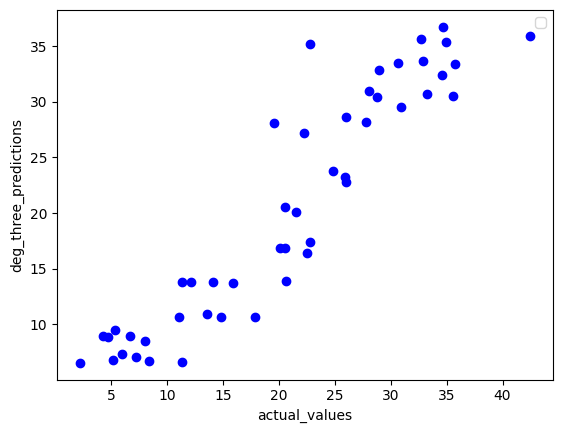

C:\Users\HP\AppData\Local\Temp\ipykernel_29056\2537544709.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


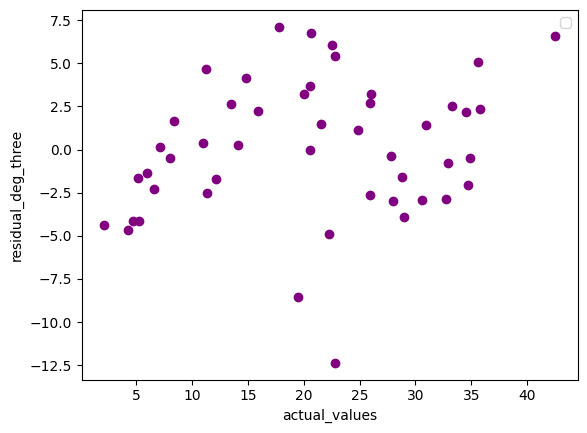

In [108]:
# polynomial_degree_three


plt.scatter( label_to_test_on ,predicted_poly_model_three , color="blue" )
plt.xlabel('actual_values')
plt.ylabel('deg_three_predictions')
plt.legend()

plt.show()


residual_deg_three = label_to_test_on - predicted_poly_model_three

plt.scatter(label_to_test_on , residual_deg_three , color='purple' )
plt.xlabel('actual_values')
plt.ylabel('residual_deg_three')
plt.legend()

plt.show()

# residuals are there and are high


C:\Users\HP\AppData\Local\Temp\ipykernel_29056\567984033.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


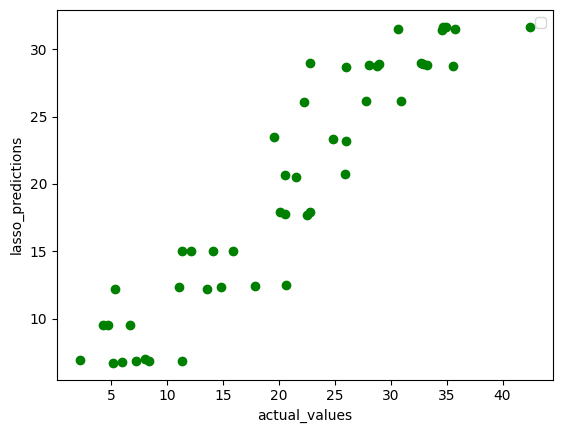

C:\Users\HP\AppData\Local\Temp\ipykernel_29056\567984033.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


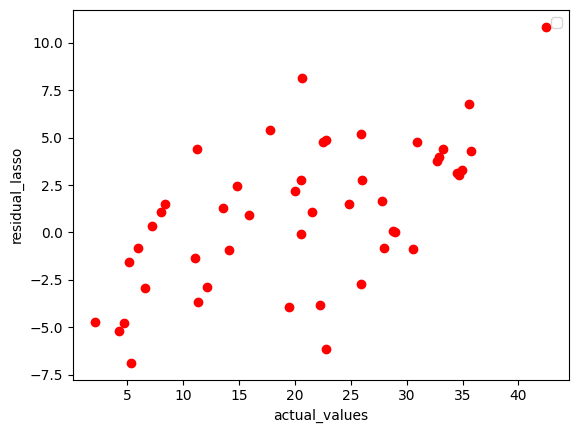

In [109]:
# lasso_regression


plt.scatter( label_to_test_on ,lasso_predictions , color="green" )
plt.xlabel('actual_values')
plt.ylabel('lasso_predictions')
plt.legend()

plt.show()


residual_lasso = label_to_test_on - lasso_predictions

plt.scatter(label_to_test_on , residual_lasso , color='red' )
plt.xlabel('actual_values')
plt.ylabel('residual_lasso')
plt.legend()

plt.show()

# residuals are there and are high


C:\Users\HP\AppData\Local\Temp\ipykernel_29056\281901580.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


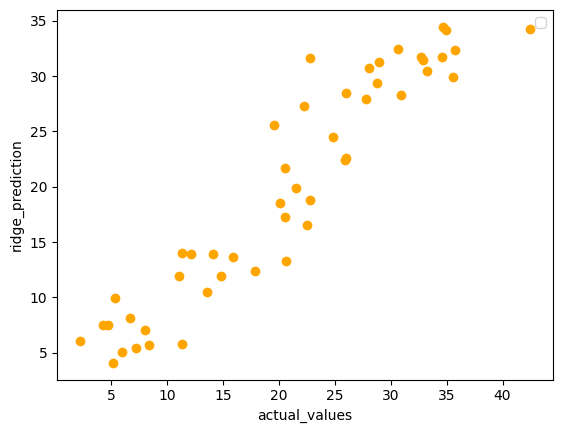

C:\Users\HP\AppData\Local\Temp\ipykernel_29056\281901580.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


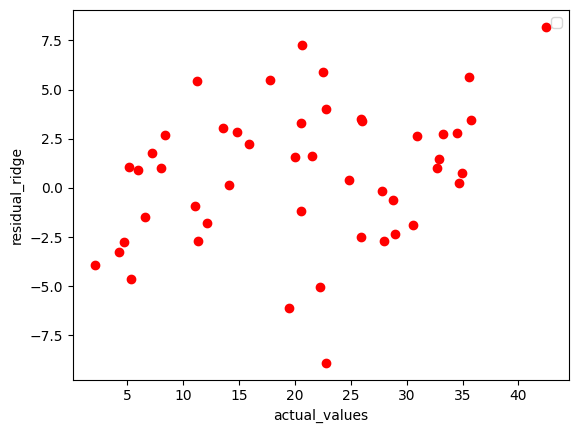

In [110]:
# ridge_regression


plt.scatter( label_to_test_on ,ridge_predictions , color="orange" )
plt.xlabel('actual_values')
plt.ylabel('ridge_prediction')
plt.legend()

plt.show()


residual_ridge = label_to_test_on - ridge_predictions

plt.scatter(label_to_test_on , residual_ridge , color='red' )
plt.xlabel('actual_values')
plt.ylabel('residual_ridge')
plt.legend()

plt.show()

# residuals are there and are high


# The model I would choose for this dataset is
# Ridge model where alpha is one , I chose it because 
# its r square is the highest meaning the ridge regression equation will cover the most variablity in the dataset.

# ANALAYSIS QUESTIONS

# 10. The dummy regressor is useful as a check point. Since it always predicts for the mean our model needs to perform better than the dummy regressor in its validation.

# 11. Ridge model with alpha = 1 has got  
# mae =  2.9052300547863106 and mse = 12.7486797281392 , which makes the rmse = 3.57053 , 
# MAE - will calculate the mean for residual
# RMSE - will calculate the sqrt of RSS / n 
# RMSE makes the errors larger if they were large and
# smaller if they were smaller , it is heavily impacted by outliers due to the squares.

# 12. Polynomials didn't improve the model due to their r_squared result being lower than the linear regression.The evidence of overfitting (or rather, unnecessary complexity hurting generalization) is that the simpler linear model achieved better test metrics than the higher-degree polynomial models.

# 13.It successfully shrunk the feature weights / slopes toward zero to prevent the model from relying too heavily on any single noisy feature. Specifically, if Lasso was used, it drove irrelevant feature weights straight to zero, performing automated feature selection.

# 14. Regualrization using Lasso and Ridge aims to penalize our model to prevent over fitting. And it makes the slope / weight of the predictors to be some value alpha , thus if there is a huge difference in scale / unit between the two it wouldn't be fair to put both predictors weight to be equal to alpha since the small one will be too much reduced and the larger would be large. That is why we scale the data beforehand. To reduce this impact.

# 15. A common leakage issue in this pipeline would be applying feature scaling (StandardScaler) to the entire dataset before splitting it into training and testing sets. This causes information about the test set's mean and standard deviation to "leak" into the training phase, making evaluation overly optimistic.

# It was handled by wrapping the scaler and the model inside a scikit-learn Pipeline (make_pipeline). This ensures the scaler learns parameters (mean/std) strictly from the training fold and applies those exact parameters to transform the test set safely without leakage.



# 16 . If tickets were collected over several years or came from repeated customers having the dataset split randomly would cause it to create mixture thus resulting in data leakage. Because the timeline is mixed the model will end up predicting the past fromt he current data. 

# 17. It would be good to check how the model performs on minority or extreme cases. And doing cross validation over the whole models would be good.